© 2026 Mechanome Bio. Proprietary and confidential.

# Nuclear vs cell shape — correlation between nuclear and cell shape metrics

**Kernel: Python** (the same environment as `nuclear_shape_prep.ipynb`; needs `spatialdata`, `shapely`, `pandas`, `numpy`, `matplotlib`).

This notebook asks one descriptive question: **how strongly is each nuclear shape metric correlated with each cell shape metric?** It does this for the same six metrics used in the other notebooks, measured on the nucleus outline and, separately, on the cell outline of the same cell.

| Step | What happens |
|---|---|
| 1 | Reads the per-cell nuclear shape table already written by `nuclear_shape_prep.ipynb` (`outputs/<tissue>/prep/cells.csv`). Nothing is re-measured for nuclei. |
| 2 | Reads the Xenium **cell outlines** (`cell_boundaries`) from the SpatialData zarr store **in place** (nothing there is changed) and measures the same six metrics with the same code (`src/nuclear_shape_metrics.py`). The result is cached in `outputs/<tissue>/prep/cell_shape_metrics.csv`, so this slow step only runs once. |
| 3 | Matches nuclei and cells by Xenium `cell_id`. |
| 4 | Draws **histograms** of every nuclear and cell metric (one panel per metric, nuclear and cell overlaid), one figure per tissue. |
| 5 | Computes the 6 × 6 Spearman correlation matrix (rows = nuclear metrics, columns = cell metrics). |
| 6 | Draws one heatmap per tissue in the house style and saves PNG, SVG and a `_metadata.json` file to `outputs/<tissue>/figures/`. |

## Choices built into this notebook

| Topic | Choice | Why / note |
|---|---|---|
| The six metrics | `solidity`, `extent`, `shape_index`, `circularity`, `perimeter`, `axis_ratio` | exactly as defined in `nuclear_shape_prep.ipynb`, measured on exact polygon geometry (not pixels) |
| Correlation | **Spearman** (rank-based) | does not assume a straight-line relationship, and is unchanged by log-transforming a metric, so it matches the "log scale" heatmaps in the plots notebook |
| Cells used | cells that appear in `cells.csv` (already passed the nucleus and count filters) **and** have a valid cell outline | the number of cells used is printed and saved in the metadata |
| Cell outline pieces | keep the largest piece, fill holes | same rule as for nuclei |
| Statistical tests | **none** (as requested) | the figure shows correlation coefficients only; no significance labels are drawn, and no p values are calculated |
| Spatial detrending | **not applied** | these are raw per-cell values, like the "before spatial detrending" heatmaps |

> **Caution when reading the results.** Xenium cell outlines are produced by a segmentation step that expands outwards from each nucleus, so a cell's outline is not an independent measurement of the cell's true boundary. Correlations between nuclear and cell metrics therefore reflect both biology and how the segmentation was done.

© 2026 Mechanome Bio. Proprietary and confidential.

In [5]:
# © 2026 Mechanome Bio. Proprietary and confidential.
# CELL 1: imports, folders and settings. Everything you might want to change is in this cell.
import sys
import json
import datetime
import platform
from pathlib import Path

import numpy
import pandas
import spatialdata
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors

# This notebook lives in nuclear_shape/notebooks, so the repository folder is one level up.
REPOSITORY_FOLDER = Path.cwd().parent
sys.path.insert(0, str(REPOSITORY_FOLDER / "src"))
import nuclear_shape_metrics as metrics   # exact polygon measurements (src/nuclear_shape_metrics.py)
import figure_style                       # Mechanome Bio house style (src/figure_style.py)

# The zarr stores are READ IN PLACE from the segmentation benchmarking repository, which sits
# next to this repository in C:\MechanomeBioRepos. Nothing in that folder is written to.
INPUT_DATA_FOLDER = REPOSITORY_FOLDER.parent / "segmentation-Pipeline-Benchmarking" / "data"
OUTPUT_FOLDER = REPOSITORY_FOLDER / "outputs"

PROPRIETARY_NOTICE = "© 2026 Mechanome Bio. Proprietary and confidential."

# Which tissues to process (each needs outputs/<tissue>/prep/cells.csv from the prep notebook).
DATASETS_TO_RUN = ["pancreas", "lung"]

# Name of the zarr store for each tissue (same stores as in nuclear_shape_prep.ipynb).
ZARR_STORE_NAMES = {
    "pancreas": "Xenium_V1_human_Pancreas_FFPE_outs.zarr",
    "lung": "Xenium_V1_humanLung_Cancer_FFPE_outs.zarr",
}

# The layer inside the zarr store that holds the whole-cell outlines.
CELL_OUTLINE_LAYER_NAME = "cell_boundaries"

# The six shape metrics, in the order used everywhere else.
SHAPE_METRICS = metrics.SHAPE_METRIC_NAMES

# Readable names for the axis tick labels.
METRIC_DISPLAY_NAMES = {
    "solidity": "Solidity", "extent": "Extent", "shape_index": "Shape index",
    "circularity": "Circularity", "perimeter": "Perimeter", "axis_ratio": "Axis ratio",
}

# Units for each metric (units go in brackets on axis labels).
METRIC_UNITS = {
    "solidity": "dimensionless", "extent": "dimensionless", "shape_index": "dimensionless",
    "circularity": "dimensionless", "perimeter": "µm", "axis_ratio": "dimensionless",
}

# Histogram settings. Each panel's x range runs from the 0.1th to the 99.9th percentile of the
# nuclear and cell values pooled together, so a handful of extreme outliers cannot squash the
# plot. The number of cells outside the range is printed and saved in the figure's metadata.
HISTOGRAM_BINS = 60
HISTOGRAM_LOWER_PERCENTILE = 0.1
HISTOGRAM_UPPER_PERCENTILE = 99.9

# True = measure the cell outlines again even if a cached table already exists.
RECOMPUTE_CELL_SHAPE = False

print("Repository folder :", REPOSITORY_FOLDER)
print("Input data folder :", INPUT_DATA_FOLDER, "(exists)" if INPUT_DATA_FOLDER.exists() else "(NOT FOUND - check the path)")
print("Tissues           :", DATASETS_TO_RUN)

Repository folder : c:\MechanomeBioRepos\nuclear_shape
Input data folder : c:\MechanomeBioRepos\segmentation-Pipeline-Benchmarking\data (exists)
Tissues           : ['pancreas', 'lung']


In [6]:
# © 2026 Mechanome Bio. Proprietary and confidential.
# CELL 2: helper functions used by the next cells.


def read_cell_outlines(zarr_path):
    '''
    Read only the cell outlines from a SpatialData zarr store (skips the large image).
    Returns a table with one row per outline: the Xenium cell_id and the outline polygon.
    '''
    try:
        spatial_data = spatialdata.read_zarr(zarr_path, selection=("shapes",))
    except TypeError:
        # Older spatialdata versions have no "selection" option; the image is read lazily anyway.
        spatial_data = spatialdata.read_zarr(zarr_path)

    if CELL_OUTLINE_LAYER_NAME not in spatial_data.shapes:
        raise KeyError(f"No '{CELL_OUTLINE_LAYER_NAME}' layer in {zarr_path.name}; "
                       f"found {list(spatial_data.shapes.keys())}")
    cell_shapes = spatial_data.shapes[CELL_OUTLINE_LAYER_NAME]

    # The Xenium cell_id is stored either as a column or as the table's index.
    if "cell_id" in cell_shapes.columns:
        outline_cell_ids = cell_shapes["cell_id"].astype(str).to_numpy()
    else:
        outline_cell_ids = cell_shapes.index.astype(str).to_numpy()
    return pandas.DataFrame({"cell_id": outline_cell_ids, "geometry": cell_shapes.geometry.to_numpy()})


def measure_cell_outlines(cell_outlines):
    '''
    Measure the six shape metrics on every cell outline.

    Cleaning is the same as for nuclei: keep the largest piece, fill holes, and drop outlines
    that are invalid or have zero area. If a cell has more than one outline, the largest is kept.
    Returns a table indexed by cell_id with columns cell_polygon_area plus the six metrics.
    '''
    cell_outlines = cell_outlines.copy()
    cell_outlines["geometry"] = [metrics.keep_largest_piece(shape) for shape in cell_outlines["geometry"]]
    is_usable = numpy.array([metrics.is_usable_polygon(shape) for shape in cell_outlines["geometry"]])
    print(f"  invalid / zero-area cell outlines dropped: {(~is_usable).sum():,}")
    cell_outlines = cell_outlines[is_usable].copy()

    # One outline per cell: keep the largest.
    cell_outlines["outline_area"] = [shape.area for shape in cell_outlines["geometry"]]
    cell_outlines = cell_outlines.sort_values("outline_area", ascending=False).drop_duplicates("cell_id")

    # measure_nucleus() works on any cleaned polygon; its area column is renamed for cells.
    measurements = pandas.DataFrame(
        [metrics.measure_nucleus(shape) for shape in cell_outlines["geometry"]],
        index=cell_outlines["cell_id"].to_numpy())
    measurements = measurements.rename(columns={"nucleus_polygon_area": "cell_polygon_area"})
    return measurements.dropna(subset=SHAPE_METRICS)


def write_csv_with_notice(data_frame, path, **to_csv_options):
    '''Write a CSV whose first line is the proprietary notice (read back with comment="#").'''
    with open(path, "w", encoding="utf-8", newline="") as output_file:
        output_file.write(f"# {PROPRIETARY_NOTICE}\n")
        data_frame.to_csv(output_file, **to_csv_options)


def spearman_correlation_matrix(nuclear_values, cell_values):
    '''
    Spearman correlation between every nuclear metric (rows) and every cell metric (columns).

    Spearman works on ranks (1st smallest, 2nd smallest, ...) instead of the raw values, so it
    picks up any relationship that always goes the same way, not only straight lines.
    '''
    nuclear_ranks = nuclear_values[SHAPE_METRICS].rank()
    cell_ranks = cell_values[SHAPE_METRICS].rank()
    matrix = pandas.DataFrame(index=SHAPE_METRICS, columns=SHAPE_METRICS, dtype=float)
    for nuclear_metric in SHAPE_METRICS:
        for cell_metric in SHAPE_METRICS:
            # Pearson correlation of the ranks = Spearman correlation of the values.
            matrix.loc[nuclear_metric, cell_metric] = nuclear_ranks[nuclear_metric].corr(cell_ranks[cell_metric])
    matrix.index.name = "nuclear_metric"
    matrix.columns.name = "cell_metric"
    return matrix


print("helper functions defined")

helper functions defined


In [7]:
# © 2026 Mechanome Bio. Proprietary and confidential.
# CELL 3: for each tissue, get the cell shape metrics (measured once, then cached) and match them
# to the nuclear shape metrics from the prep notebook.

paired_tables = {}   # tissue name -> table with nuclear_<metric> and cell_<metric> columns

for dataset_name in DATASETS_TO_RUN:
    prep_folder = OUTPUT_FOLDER / dataset_name / "prep"
    nuclear_table_path = prep_folder / "cells.csv"
    cell_shape_cache_path = prep_folder / "cell_shape_metrics.csv"
    print(f"\n========== {dataset_name} ==========")

    if not nuclear_table_path.exists():
        print(f"  no {nuclear_table_path.relative_to(REPOSITORY_FOLDER)} - run nuclear_shape_prep.ipynb first")
        continue

    # ---- Nuclear metrics (already measured by the prep notebook) ---------------------------
    nuclear_table = pandas.read_csv(nuclear_table_path, comment="#", index_col="cell_id")
    nuclear_table.index = nuclear_table.index.astype(str)
    print(f"  nuclear table: {len(nuclear_table):,} cells")

    # ---- Cell metrics (measured here, cached afterwards) -----------------------------------
    if cell_shape_cache_path.exists() and not RECOMPUTE_CELL_SHAPE:
        cell_measurements = pandas.read_csv(cell_shape_cache_path, comment="#", index_col="cell_id")
        cell_measurements.index = cell_measurements.index.astype(str)
        print(f"  cell metrics read from cache: {cell_shape_cache_path.name} ({len(cell_measurements):,} cells)")
    else:
        zarr_path = INPUT_DATA_FOLDER / ZARR_STORE_NAMES[dataset_name]
        print(f"  measuring cell outlines from {zarr_path.name} (this can take a few minutes)")
        cell_outlines = read_cell_outlines(zarr_path)
        # Only measure cells we will actually use.
        cell_outlines = cell_outlines[cell_outlines["cell_id"].isin(set(nuclear_table.index))]
        print(f"  cell outlines matching the nuclear table: {len(cell_outlines):,}")
        cell_measurements = measure_cell_outlines(cell_outlines)
        cell_measurements.index.name = "cell_id"
        write_csv_with_notice(cell_measurements, cell_shape_cache_path, index=True)
        print(f"  saved {cell_shape_cache_path.relative_to(REPOSITORY_FOLDER)}")

    # ---- Match nuclei and cells by Xenium cell_id ------------------------------------------
    matched_cell_ids = nuclear_table.index.intersection(cell_measurements.index)
    paired = pandas.DataFrame(index=matched_cell_ids)
    for metric_name in SHAPE_METRICS:
        paired[f"nuclear_{metric_name}"] = nuclear_table.loc[matched_cell_ids, metric_name].to_numpy()
        paired[f"cell_{metric_name}"] = cell_measurements.loc[matched_cell_ids, metric_name].to_numpy()
    paired = paired.replace([numpy.inf, -numpy.inf], numpy.nan).dropna()
    paired_tables[dataset_name] = paired
    print(f"  cells with both nuclear and cell metrics: {len(paired):,} "
          f"(of {len(nuclear_table):,} in the nuclear table)")

    # Quick check that the outlines are sensible: the polygon area should be close to the area
    # Xenium itself reports for the cell (both in square microns).
    if "cell_polygon_area" in cell_measurements.columns and "cell_area" in nuclear_table.columns:
        area_ratio = (cell_measurements.loc[matched_cell_ids, "cell_polygon_area"]
                      / nuclear_table.loc[matched_cell_ids, "cell_area"])
        print(f"  check: cell outline area / Xenium cell_area, median = {area_ratio.median():.3f} "
              f"(5th-95th percentile {area_ratio.quantile(0.05):.3f} - {area_ratio.quantile(0.95):.3f})")

    display(paired[[f"cell_{name}" for name in SHAPE_METRICS]].describe().T)


========== pancreas ==========
  nuclear table: 112,909 cells
  cell metrics read from cache: cell_shape_metrics.csv (112,846 cells)
  cells with both nuclear and cell metrics: 112,846 (of 112,909 in the nuclear table)
  check: cell outline area / Xenium cell_area, median = 0.950 (5th-95th percentile 0.917 - 0.970)


,count,mean,std,min,25%,50%,75%,max
cell_solidity,112846.0,0.920819,0.053430,0.514159,0.894492,0.933079,0.960076,1.000000
cell_extent,112846.0,0.619411,0.095853,0.137656,0.563887,0.629488,0.686952,0.898058
cell_shape_index,112846.0,4.226531,0.410713,3.570333,3.945659,4.132180,4.400319,8.785790
cell_circularity,112846.0,0.720716,0.119439,0.162798,0.648995,0.735955,0.807181,0.985808
cell_perimeter,112846.0,32.438797,9.984104,8.934218,25.491110,31.096541,37.658513,130.877203
cell_axis_ratio,112846.0,0.602165,0.176267,0.083171,0.477550,0.608765,0.734816,0.998703



========== lung ==========
  nuclear table: 140,259 cells
  cell metrics read from cache: cell_shape_metrics.csv (140,160 cells)
  cells with both nuclear and cell metrics: 140,160 (of 140,259 in the nuclear table)
  check: cell outline area / Xenium cell_area, median = 0.952 (5th-95th percentile 0.918 - 0.971)


,count,mean,std,min,25%,50%,75%,max
cell_solidity,140160.0,0.920828,0.053585,0.464051,0.895532,0.932773,0.959168,1.000000
cell_extent,140160.0,0.621788,0.091968,0.158343,0.567202,0.628757,0.686497,0.937492
cell_shape_index,140160.0,4.195449,0.362874,3.567601,3.953522,4.123774,4.353089,8.030649
cell_circularity,140160.0,0.728026,0.109699,0.194854,0.663155,0.738959,0.803973,0.987319
cell_perimeter,140160.0,33.538063,10.724052,9.532312,25.422695,31.983596,39.830721,104.099849
cell_axis_ratio,140160.0,0.620626,0.168970,0.091530,0.500892,0.626176,0.747624,0.999712



========== pancreas ==========


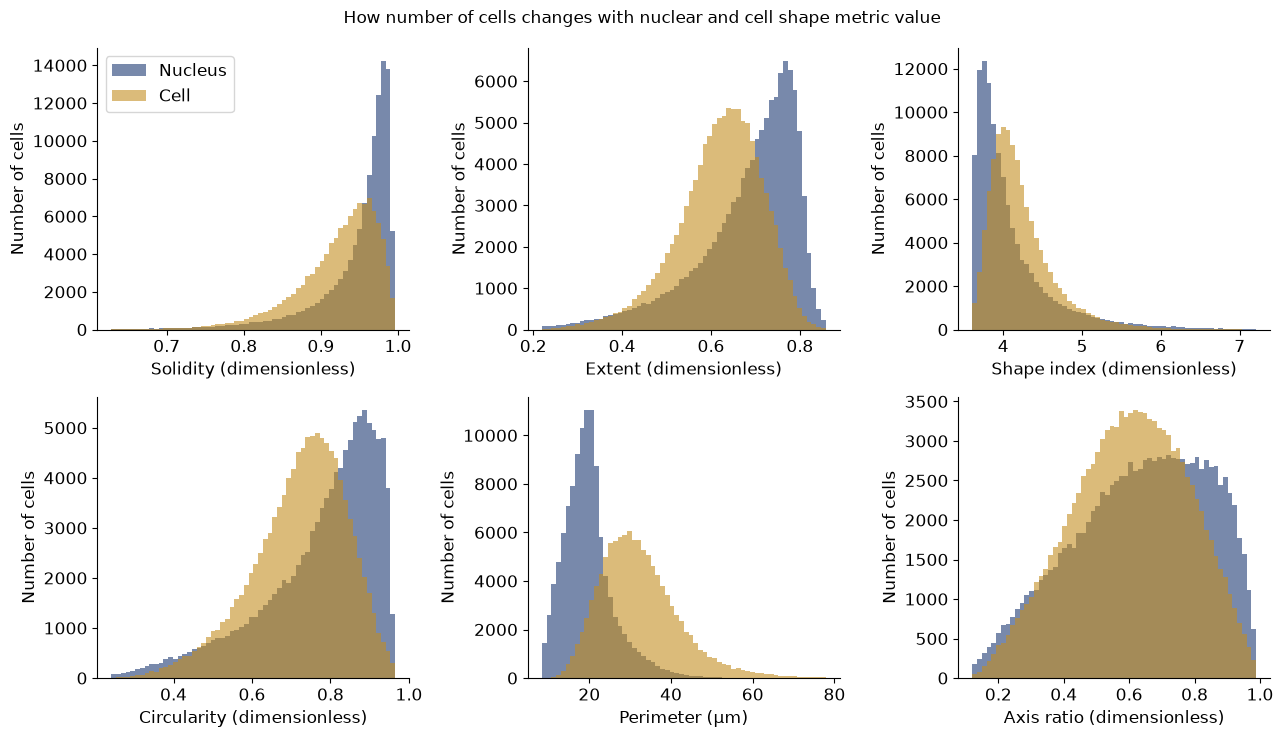


========== lung ==========


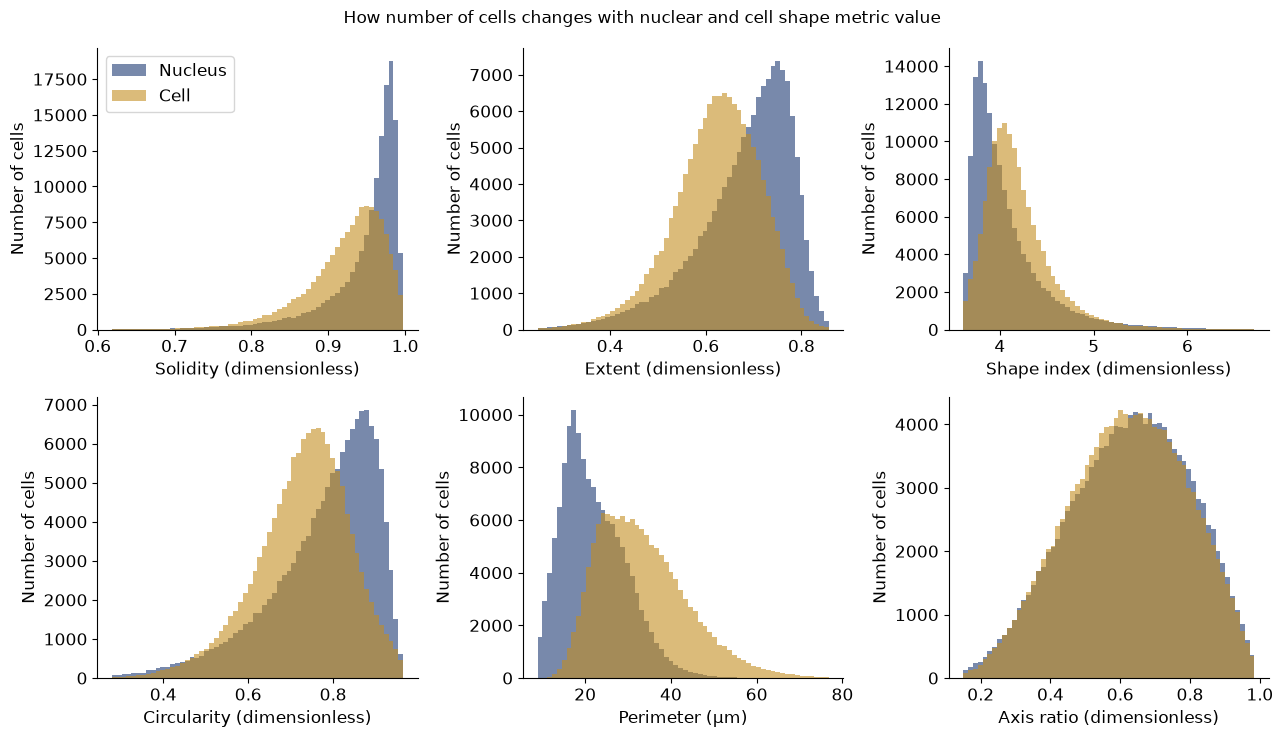

In [8]:
# © 2026 Mechanome Bio. Proprietary and confidential.
# CELL 4: histograms of every nuclear and cell shape metric (one figure per tissue).


def plot_metric_distributions(paired, dataset_name):
    '''One panel per metric: histogram of the nuclear values and of the cell values, overlaid.'''
    # Two colours are used because colour tells the two outlines apart (the axes do not).
    nuclear_colour, cell_colour = figure_style.get_colours(2)

    figure, axes_grid = plt.subplots(2, 3, figsize=(13, 7.5))
    cells_outside_range = {}
    for axes, metric_name in zip(axes_grid.ravel(), SHAPE_METRICS):
        nuclear_values = paired[f"nuclear_{metric_name}"].to_numpy()
        cell_values = paired[f"cell_{metric_name}"].to_numpy()

        # Same bins for both histograms so their bars line up and can be compared directly.
        pooled_values = numpy.concatenate([nuclear_values, cell_values])
        range_low, range_high = numpy.percentile(
            pooled_values, [HISTOGRAM_LOWER_PERCENTILE, HISTOGRAM_UPPER_PERCENTILE])
        if range_high - range_low < 1e-9:
            # A metric that is (almost) constant would give zero-width bins and an empty plot.
            range_low, range_high = range_low - 0.01, range_high + 0.01
        bin_edges = numpy.linspace(range_low, range_high, HISTOGRAM_BINS + 1)
        cells_outside_range[metric_name] = {
            "nuclear": int(((nuclear_values < range_low) | (nuclear_values > range_high)).sum()),
            "cell": int(((cell_values < range_low) | (cell_values > range_high)).sum()),
            "x_range": [float(range_low), float(range_high)],
        }

        axes.hist(nuclear_values, bins=bin_edges, color=nuclear_colour, alpha=0.6, label="Nucleus")
        axes.hist(cell_values, bins=bin_edges, color=cell_colour, alpha=0.6, label="Cell")
        axes.set_xlabel(f"{METRIC_DISPLAY_NAMES[metric_name]} ({METRIC_UNITS[metric_name]})")
        axes.set_ylabel("Number of cells")
    axes_grid[0, 0].legend()   # colours are the same in every panel, so one legend is enough

    title = figure_style.make_title("Number of cells", "nuclear and cell shape metric value")
    figure.suptitle(title)
    figure.tight_layout()

    figure_folder = OUTPUT_FOLDER / dataset_name / "figures"
    figure_folder.mkdir(parents=True, exist_ok=True)
    figure_style.save_figure(
        figure, str(figure_folder / "nuclear_and_cell_metric_distributions"), title,
        "Shape metric value (one metric per panel)", "Number of cells",
        comparison_results=None,
        extra_information={
            "dataset": dataset_name,
            "notebook": "notebooks/nuclear_cell_shape_correlation.ipynb",
            "number_of_cells": int(len(paired)),
            "series": {"Nucleus": "nucleus outline metrics (nuclear_shape_prep.ipynb)",
                       "Cell": f"Xenium {CELL_OUTLINE_LAYER_NAME} outline metrics"},
            "histogram_bins": HISTOGRAM_BINS,
            "x_range_percentiles": [HISTOGRAM_LOWER_PERCENTILE, HISTOGRAM_UPPER_PERCENTILE],
            "cells_outside_x_range": cells_outside_range,
            "source_table": [str((OUTPUT_FOLDER / dataset_name / "prep" / name).relative_to(REPOSITORY_FOLDER))
                             for name in ("cells.csv", "cell_shape_metrics.csv")],
            "statistical_comparisons": "No statistical tests performed (user declined).",
        })
    plt.show()
    plt.close(figure)


figure_style.apply_house_style()

for dataset_name, paired in paired_tables.items():
    print(f"\n========== {dataset_name} ==========")
    plot_metric_distributions(paired, dataset_name)


========== pancreas ==========
  saved outputs\pancreas\plot_data\nuclear_vs_cell_shape_correlation.csv


cell_metric,solidity,extent,shape_index,circularity,perimeter,axis_ratio
nuclear_metric,,,,,,
solidity,0.480,0.368,-0.531,0.531,0.095,0.366
extent,0.409,0.525,-0.505,0.505,-0.034,0.414
shape_index,-0.478,-0.426,0.618,-0.618,-0.026,-0.516
circularity,0.478,0.426,-0.618,0.618,0.026,0.516
perimeter,-0.145,-0.139,0.136,-0.136,0.663,-0.120
axis_ratio,0.374,0.388,-0.558,0.558,-0.060,0.582


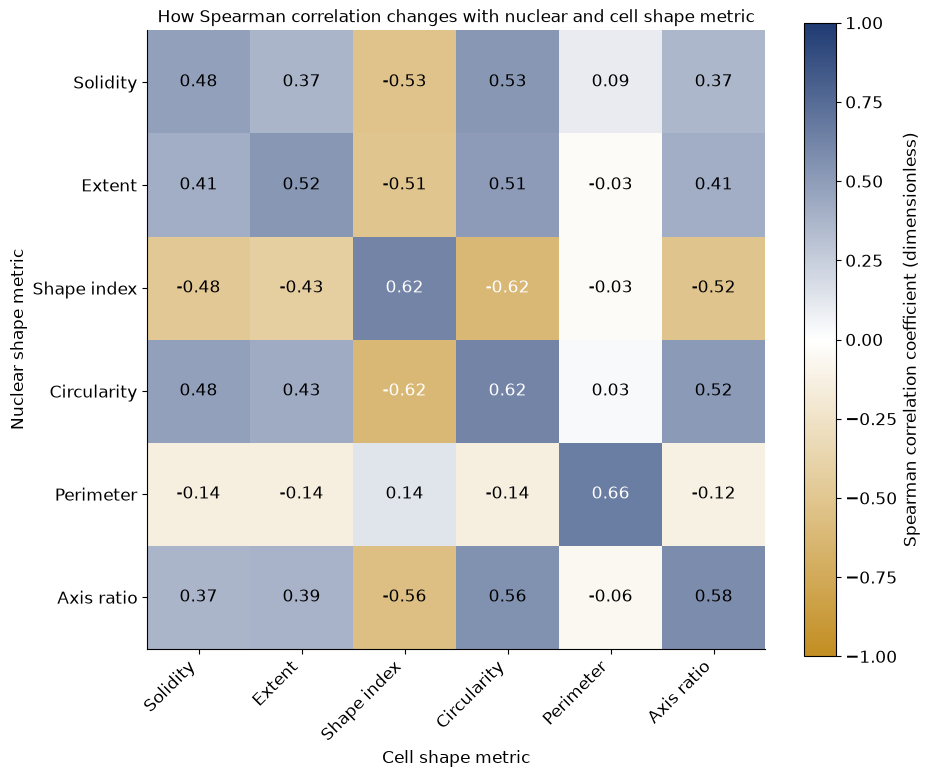


========== lung ==========
  saved outputs\lung\plot_data\nuclear_vs_cell_shape_correlation.csv


cell_metric,solidity,extent,shape_index,circularity,perimeter,axis_ratio
nuclear_metric,,,,,,
solidity,0.465,0.329,-0.475,0.475,0.094,0.274
extent,0.388,0.550,-0.485,0.485,-0.135,0.399
shape_index,-0.469,-0.433,0.608,-0.608,0.057,-0.504
circularity,0.469,0.433,-0.608,0.608,-0.057,0.504
perimeter,-0.118,-0.163,0.157,-0.157,0.804,-0.197
axis_ratio,0.328,0.394,-0.534,0.534,-0.215,0.630


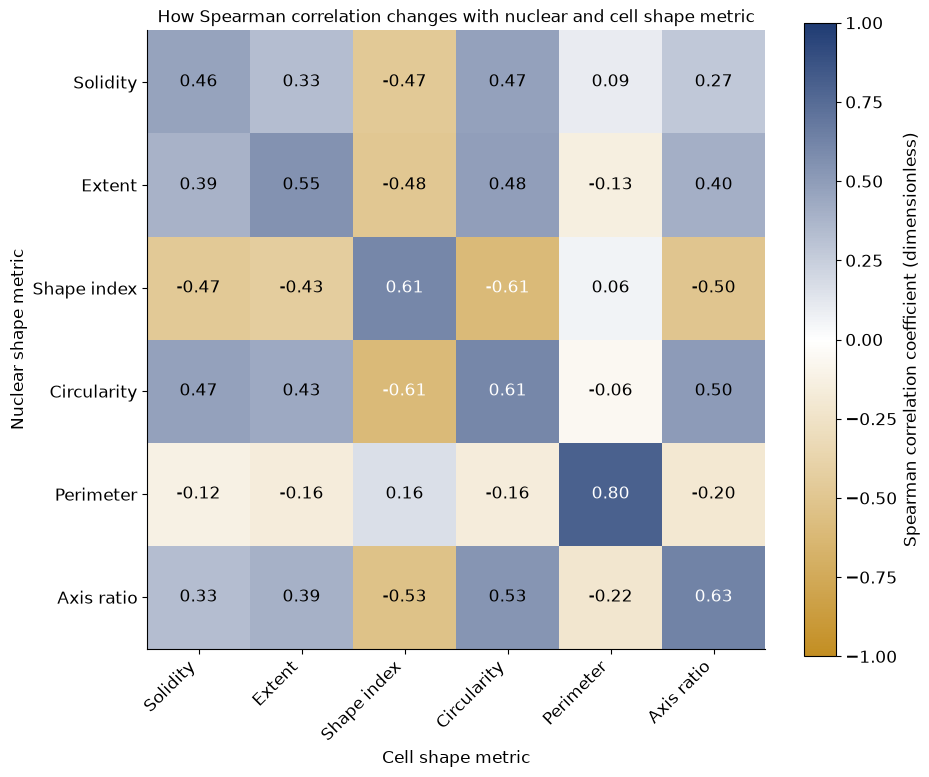

In [9]:
# © 2026 Mechanome Bio. Proprietary and confidential.
# CELL 5: correlation matrix and heatmap for each tissue.


def plot_nuclear_vs_cell_heatmap(correlation, dataset_name, number_of_cells, source_tables):
    '''Spearman correlation between nuclear metrics (rows) and cell metrics (columns).'''
    display_names = [METRIC_DISPLAY_NAMES[name] for name in SHAPE_METRICS]

    # Same colour scale as the correlation heatmaps in the plots notebook:
    # two house colours with white at zero correlation.
    house_colours = figure_style.get_colours(2)
    colour_scale = matplotlib.colors.LinearSegmentedColormap.from_list(
        "mechanome_correlation", [house_colours[1], "#FFFFFF", house_colours[0]])

    figure, axes = plt.subplots(figsize=(1.0 * len(display_names) + 3.5, 0.9 * len(display_names) + 2.5))
    image = axes.imshow(correlation.to_numpy(dtype=float), cmap=colour_scale, vmin=-1, vmax=1)
    axes.set_xticks(range(len(display_names)))
    axes.set_xticklabels(display_names, rotation=45, ha="right")
    axes.set_yticks(range(len(display_names)))
    axes.set_yticklabels(display_names)

    # Write the coefficient in each square (white text on dark squares so it stays readable).
    for row in range(len(display_names)):
        for column in range(len(display_names)):
            value = correlation.iloc[row, column]
            axes.text(column, row, f"{value:.2f}", ha="center", va="center",
                      color="white" if abs(value) > 0.6 else "black")

    colour_bar = figure.colorbar(image, ax=axes)
    colour_bar.set_label("Spearman correlation coefficient (dimensionless)")
    x_label = "Cell shape metric"
    y_label = "Nuclear shape metric"
    axes.set_xlabel(x_label)
    axes.set_ylabel(y_label)
    # Written out by hand (still "How y changes with x") so "Spearman", a name, keeps its capital S.
    title = "How Spearman correlation changes with nuclear and cell shape metric"
    axes.set_title(title)
    figure.tight_layout()

    figure_folder = OUTPUT_FOLDER / dataset_name / "figures"
    figure_folder.mkdir(parents=True, exist_ok=True)
    figure_style.save_figure(
        figure, str(figure_folder / "nuclear_vs_cell_shape_correlation"), title, x_label, y_label,
        comparison_results=None,
        extra_information={
            "dataset": dataset_name,
            "notebook": "notebooks/nuclear_cell_shape_correlation.ipynb",
            "correlation_method": "spearman",
            "number_of_cells": int(number_of_cells),
            "rows": "nuclear shape metrics (nucleus outline, from nuclear_shape_prep.ipynb)",
            "columns": f"cell shape metrics (Xenium {CELL_OUTLINE_LAYER_NAME} outline, measured with the same code)",
            "metric_definitions": {
                "solidity": "area / convex hull area",
                "extent": "area / axis-aligned bounding box area",
                "shape_index": "perimeter / sqrt(area)",
                "circularity": "4 * pi * area / perimeter^2",
                "perimeter": "outline length (microns)",
                "axis_ratio": "minor / major axis of the equivalent ellipse (second moments of area)",
            },
            "source_table": [str(path.relative_to(REPOSITORY_FOLDER)) for path in source_tables],
            "statistical_comparisons": "No statistical tests performed (user declined); correlation coefficients only.",
        })
    plt.show()
    plt.close(figure)


figure_style.apply_house_style()

for dataset_name, paired in paired_tables.items():
    print(f"\n========== {dataset_name} ==========")
    correlation = spearman_correlation_matrix(
        paired[[f"nuclear_{name}" for name in SHAPE_METRICS]].rename(columns=lambda c: c.replace("nuclear_", "")),
        paired[[f"cell_{name}" for name in SHAPE_METRICS]].rename(columns=lambda c: c.replace("cell_", "")))

    # Save the numbers behind the figure, so the figure can be redrawn without re-measuring.
    plot_data_folder = OUTPUT_FOLDER / dataset_name / "plot_data"
    plot_data_folder.mkdir(parents=True, exist_ok=True)
    correlation_path = plot_data_folder / "nuclear_vs_cell_shape_correlation.csv"
    write_csv_with_notice(correlation, correlation_path, index=True)
    print(f"  saved {correlation_path.relative_to(REPOSITORY_FOLDER)}")

    display(correlation.round(3))
    plot_nuclear_vs_cell_heatmap(
        correlation, dataset_name, len(paired),
        source_tables=[OUTPUT_FOLDER / dataset_name / "prep" / "cells.csv",
                       OUTPUT_FOLDER / dataset_name / "prep" / "cell_shape_metrics.csv",
                       correlation_path])

### Outputs

For each tissue, in `outputs/<tissue>/`:

- `prep/cell_shape_metrics.csv` — the six metrics measured on each cell outline (cached)
- `figures/nuclear_and_cell_metric_distributions.png`, `.svg` and `_metadata.json` — histograms of every nuclear and cell metric
- `plot_data/nuclear_vs_cell_shape_correlation.csv` — the 6 × 6 Spearman matrix (rows = nuclear, columns = cell)
- `figures/nuclear_vs_cell_shape_correlation.png`, `.svg` and `_metadata.json`

© 2026 Mechanome Bio. Proprietary and confidential.